# How Stable Are Small LLM Reviewers? — Pilot Study

**Question:** If a small open LLM "reviews" an ICLR 2024 paper (title + abstract) using four prompts that ask for the
*same* 1–10 judgement in slightly different words, how often does its score / accept-reject verdict change?
And does it agree with the real human reviewers?

**Kaggle settings (right sidebar → Session options):** Accelerator = **GPU T4 x2** or **P100**, Internet = **On**.
Run cells top to bottom (*Run All* works). Outputs land in `/kaggle/working/` → download them from the **Output** tab.
If the session dies, just *Run All* again — scoring resumes where it stopped.

## 1. Configuration

In [15]:
import os, re, json, random
import numpy as np
import pandas as pd

MODEL_IDS = ["Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-3B-Instruct",
             "Qwen/Qwen2.5-7B-Instruct"]   # three sizes → "does scale help?" (7B needs GPU T4 x2; drop it on P100)
DATASET_ID = "smallari/openreview-iclr2024-peer-reviews-RAW"           # public mirror of OpenReview ICLR 2024
N_PER_CLASS = 30        # 30 accepted + 30 rejected papers
SEED = 42
ACCEPT_THRESHOLD = 6    # greedy score >= 6 counts as an absolute "accept" (ICLR's 6 = "marginally above threshold")
ACCEPT_RATE = 0.31      # relative verdict: top 31% per prompt = accept (ICLR 2024's real acceptance rate)
N_BOOT = 1000           # bootstrap resamples for 95% confidence intervals
BATCH_SIZE = 4

OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
os.makedirs(f"{OUT}/data", exist_ok=True)
os.makedirs(f"{OUT}/results", exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)

## 2. Data: 60 ICLR 2024 papers with human ratings

In [16]:
from datasets import load_dataset

raw = load_dataset(DATASET_ID, split="raw").to_pandas()
print(raw.shape)
print(raw["decision"].value_counts())

def human_ratings(reviews):
    """Each review's rating looks like '6: marginally above the acceptance threshold' -> 6."""
    out = []
    for r in (reviews if reviews is not None else []):
        m = re.match(r"\s*(\d+)", r.get("rating") or "")
        if m:
            out.append(int(m.group(1)))
    return out

raw["ratings"] = raw["reviews"].apply(human_ratings)
df = raw[(raw["year"] == "2024")
         & raw["label"].isin([0, 1])
         & raw["abstract"].fillna("").str.strip().astype(bool)
         & (raw["ratings"].str.len() >= 3)].drop_duplicates("paper_id").copy()
df["n_reviews"] = df["ratings"].str.len()
df["human_mean"] = df["ratings"].apply(np.mean)
df["human_std"] = df["ratings"].apply(np.std)   # disagreement between human reviewers

papers = pd.concat([df[df["label"] == lab].sample(N_PER_CLASS, random_state=SEED) for lab in (1, 0)])
papers = papers[["paper_id", "title", "abstract", "decision", "label",
                 "n_reviews", "human_mean", "human_std", "ratings"]].reset_index(drop=True)
papers.to_csv(f"{OUT}/data/papers.csv", index=False)

assert len(papers) == 2 * N_PER_CLASS
print(papers.groupby("label")[["human_mean", "human_std", "n_reviews"]].mean().round(2))

(7404, 8)
decision
Reject                3519
Accept (poster)       1808
Accept (spotlight)     367
Accept (oral)           86
Name: count, dtype: int64
       human_mean  human_std  n_reviews
label                                  
0            4.62       1.00       3.97
1            6.37       0.89       3.93


## 3. Four reviewer prompts
All four ask for the same thing (an overall 1–10 score from title + abstract). They differ only in
**wording**, **layout**, and **where the instruction sits** — features that should not change a good reviewer's score.

In [17]:
PROMPTS = {
    # role-play framing, instruction before content
    "P1_expert": ("You are an expert reviewer for ICLR. Read the title and abstract below and rate the paper's "
                  "overall quality on a scale from 1 (strong reject) to 10 (strong accept). "
                  "Respond with a single integer only.\n\nTitle: {title}\n\nAbstract: {abstract}"),
    # plain task description, no role
    "P2_plain": ("Below is a submission to the ICLR conference. As a reviewer, score it from 1 to 10, where 10 means "
                 "a clear accept and 1 means a clear reject. Output just the number.\n\n"
                 "Title: {title}\nAbstract: {abstract}"),
    # same content, instruction AFTER the paper
    "P3_after": ("Title: {title}\n\nAbstract: {abstract}\n\nYou are reviewing this paper for ICLR, a top machine "
                 "learning conference. On a 1-10 scale (1 = strong reject, 10 = strong accept), what score would you "
                 "give? Reply with one integer and nothing else."),
    # terse, markdown-structured format
    "P4_terse": ("Rate this ICLR submission.\nScale: 1 (definitely reject) to 10 (definitely accept).\n"
                 "Format: a single integer.\n\n### Title\n{title}\n\n### Abstract\n{abstract}"),
}

## 4. Score every paper × prompt × model
Two scores per call:
* **greedy score** — the single number the model writes (deterministic decoding)
* **expected score** — the probability-weighted average over the answers 1…10, read from the model's
  next-token probabilities. Greedy outputs collapse onto one value (v1 pilot: almost always "8");
  the expected score keeps the model's uncertainty, so small prompt effects become measurable.

In [18]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

SCORES_CSV = f"{OUT}/results/scores_v2.csv"   # new file: v1 scores have no expected score

def parse_score(text):
    """First integer 1-10 in the model's reply, else NaN."""
    m = re.search(r"\b(10|[1-9])\b", text)
    return int(m.group(1)) if m else np.nan

def expected_scores(model, enc, digit_ids):
    """Probability-weighted 1-10 score from the first answer token.
    Qwen writes numbers digit by digit, so "1" is ambiguous ("1" or "10"): a second pass reads P("0" | "1")."""
    def last_probs(input_ids, attention_mask):
        pos = (attention_mask.cumsum(-1) - 1).clamp(min=0)          # correct positions under left padding
        logits = model(input_ids=input_ids, attention_mask=attention_mask, position_ids=pos).logits[:, -1, :]
        return logits.float().softmax(-1)
    with torch.no_grad():
        p = last_probs(enc["input_ids"], enc["attention_mask"])[:, digit_ids]          # P(first token = "0".."9")
        one = torch.full((p.shape[0], 1), digit_ids[1], device=enc["input_ids"].device)
        q = last_probs(torch.cat([enc["input_ids"], one], 1),
                       torch.cat([enc["attention_mask"], torch.ones_like(one)], 1))[:, digit_ids[0]]  # P("10" | "1...")
    mass = p[:, 1:].sum(1)                                                              # prob. of answering with 1-10
    num = (p[:, 2:] * torch.arange(2, 10, device=p.device)).sum(1) + p[:, 1] * ((1 - q) * 1 + q * 10)
    return (num / mass).cpu().numpy(), mass.cpu().numpy()

done = pd.read_csv(SCORES_CSV) if os.path.exists(SCORES_CSV) else pd.DataFrame(columns=["model", "paper_id", "prompt_id"])
done_keys = set(zip(done["model"], done["paper_id"], done["prompt_id"]))

for model_id in MODEL_IDS:
    jobs = [(p.paper_id, pid, tmpl.format(title=p.title.strip(), abstract=p.abstract.strip()))
            for p in papers.itertuples() for pid, tmpl in PROMPTS.items()
            if (model_id, p.paper_id, pid) not in done_keys]
    if not jobs:
        print("already done:", model_id)
        continue
    tok = AutoTokenizer.from_pretrained(model_id, padding_side="left")
    model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float16, device_map="auto").eval()
    digit_ids = [tok.convert_tokens_to_ids(str(d)) for d in range(10)]
    for i in range(0, len(jobs), BATCH_SIZE):
        batch = jobs[i:i + BATCH_SIZE]
        texts = [tok.apply_chat_template([{"role": "user", "content": c}], tokenize=False, add_generation_prompt=True)
                 for _, _, c in batch]
        enc = tok(texts, return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=8, do_sample=False, temperature=None, top_p=None, top_k=None,
                                 pad_token_id=tok.pad_token_id)
        outs = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        exp, mass = expected_scores(model, enc, digit_ids)
        rows = [{"model": model_id, "paper_id": pid, "prompt_id": pr, "raw_output": o.strip(), "score": parse_score(o),
                 "exp_score": e, "digit_mass": m}
                for (pid, pr, _), o, e, m in zip(batch, outs, exp, mass)]
        # append after every batch so a crash never loses finished work
        pd.DataFrame(rows).to_csv(SCORES_CSV, mode="a", header=not os.path.exists(SCORES_CSV), index=False)
        print(f"{model_id}: {min(i + BATCH_SIZE, len(jobs))}/{len(jobs)}", end="\r")
    print()
    del model
    torch.cuda.empty_cache()

already done: Qwen/Qwen2.5-1.5B-Instruct
already done: Qwen/Qwen2.5-3B-Instruct
already done: Qwen/Qwen2.5-7B-Instruct


## 5. Sanity checks
Targets: greedy parse rate ≥ 0.95; `digit_mass` (probability the model answers with a number) close to 1.

In [19]:
scores = pd.read_csv(SCORES_CSV)
print("rows:", len(scores))
print(scores.groupby("model").agg(parse_rate=("score", lambda s: s.notna().mean()),
                                  digit_mass=("digit_mass", "mean"),
                                  exp_score_mean=("exp_score", "mean")).round(3))
print("\ngreedy score distribution (share of outputs):")
print(pd.crosstab(scores["model"], scores["score"], normalize="index").round(2))
print(scores.sample(5, random_state=SEED)[["model", "prompt_id", "raw_output", "score", "exp_score"]].to_string())

rows: 720
                            parse_rate  digit_mass  exp_score_mean
model                                                             
Qwen/Qwen2.5-1.5B-Instruct         1.0       0.982           8.156
Qwen/Qwen2.5-3B-Instruct           1.0       1.000           8.075
Qwen/Qwen2.5-7B-Instruct           1.0       1.000           8.260

greedy score distribution (share of outputs):
score                         6     7     8     9     10
model                                                   
Qwen/Qwen2.5-1.5B-Instruct  0.01  0.00  0.71  0.28  0.00
Qwen/Qwen2.5-3B-Instruct    0.02  0.04  0.86  0.07  0.01
Qwen/Qwen2.5-7B-Instruct    0.00  0.01  0.69  0.30  0.00
                          model  prompt_id raw_output  score  exp_score
340    Qwen/Qwen2.5-3B-Instruct  P1_expert          8      8   8.238621
290    Qwen/Qwen2.5-3B-Instruct   P3_after          8      8   8.098483
54   Qwen/Qwen2.5-1.5B-Instruct   P3_after          8      8   8.132757
198  Qwen/Qwen2.5-1.5B-Instruct   P

## 6. Metrics
* **Leniency** — greedy: most common score and share of papers "accepted" (≥6). Real acceptance rate: 31%.
* **Stability** (expected score) — per-paper std across prompts; rank agreement between prompts (Spearman);
  **verdict flip rate** with relative verdicts (top 31% per prompt = accept), next to what random rankings would give.
* **Agreement with humans** — Spearman ρ vs mean human rating and AUC for accepted vs rejected, with 95% bootstrap CIs.
* **Prompt-averaged score** — does averaging over prompts help? (seed idea for a later paper)

In [20]:
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

meta = papers.set_index("paper_id")
rng = np.random.default_rng(SEED)

def wide_scores(model_id, col="exp_score"):
    s = scores[scores["model"] == model_id].dropna(subset=[col])
    return s.pivot_table(index="paper_id", columns="prompt_id", values=col).dropna()   # papers scored by every prompt

def boot_ci(x, y, stat):
    x, y = np.asarray(x), np.asarray(y)
    vals = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(x), len(x))
        if len(np.unique(y[i])) > 1:
            vals.append(stat(x[i], y[i]))
    return np.nanpercentile(vals, [2.5, 97.5]).tolist()

rho = lambda x, y: spearmanr(x, y)[0]

def agreement(x, y):
    return {"spearman_vs_human": rho(x, y["human_mean"]), "spearman_ci": boot_ci(x, y["human_mean"], rho),
            "auc_accept": roc_auc_score(y["label"], x), "auc_ci": boot_ci(x, y["label"], lambda a, b: roc_auc_score(b, a))}

metrics = {}
for model_id in MODEL_IDS:
    wide, greedy = wide_scores(model_id), wide_scores(model_id, "score")
    y = meta.loc[wide.index]
    k = round(ACCEPT_RATE * len(wide))
    top = wide.rank(ascending=False, method="first") <= k                    # relative accept verdict per prompt
    n_p = wide.shape[1]
    pair = wide.corr(method="spearman").values[np.triu_indices(n_p, 1)]
    greedy_vals = greedy.values.ravel()
    mode = pd.Series(greedy_vals).mode()[0]
    metrics[model_id] = {
        "n_papers": len(wide),
        "greedy_mode": mode,
        "greedy_mode_share": (greedy_vals == mode).mean(),
        "greedy_accept_share_ge6": (greedy_vals >= ACCEPT_THRESHOLD).mean(),
        "exp_score_std_across_prompts": wide.std(axis=1, ddof=0).mean(),
        "prompt_rank_agreement_mean": pair.mean(),
        "prompt_rank_agreement_min": pair.min(),
        "verdict_flip_rate_top31": (top.nunique(axis=1) > 1).mean(),
        "verdict_flip_rate_random_baseline": 1 - ACCEPT_RATE ** n_p - (1 - ACCEPT_RATE) ** n_p,
        "human_reviewer_std_mean": y["human_std"].mean(),
        "per_prompt": {p: {"mean_exp_score": wide[p].mean(), **agreement(wide[p], y)} for p in wide.columns},
        "prompt_averaged": {"mean_exp_score": wide.mean(axis=1).mean(), **agreement(wide.mean(axis=1), y)},
        "prompt_pair_spearman": wide.corr(method="spearman").round(3).to_dict(),
    }

with open(f"{OUT}/results/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)

# two markdown tables you can paste straight into the paper / README
short = lambda m: m.split("/")[-1].replace("-Instruct", "")
ci = lambda v, c: f"{v:.2f} [{c[0]:.2f}, {c[1]:.2f}]"
lines = ["**Table 1. Leniency and stability across prompts**", "",
         "| Model | Most common greedy score (share) | Greedy 'accept' (≥6) | Exp.-score std across prompts | "
         "Prompt rank agreement ρ (mean / min) | Verdict flip rate, top-31% (random) |",
         "|---|---|---|---|---|---|"]
for model_id, m in metrics.items():
    lines.append(f"| {short(model_id)} | {m['greedy_mode']:.0f} ({m['greedy_mode_share']:.0%}) | {m['greedy_accept_share_ge6']:.0%} | "
                 f"{m['exp_score_std_across_prompts']:.2f} | {m['prompt_rank_agreement_mean']:.2f} / {m['prompt_rank_agreement_min']:.2f} | "
                 f"{m['verdict_flip_rate_top31']:.0%} ({m['verdict_flip_rate_random_baseline']:.0%}) |")
lines += ["", "**Table 2. Agreement with human reviewers (expected score, 95% bootstrap CI)**", "",
          "| Model | Prompt | Mean exp. score | Spearman ρ vs human mean | AUC accepted vs rejected |", "|---|---|---|---|---|"]
for model_id, m in metrics.items():
    for p, v in list(m["per_prompt"].items()) + [("avg of prompts", m["prompt_averaged"])]:
        lines.append(f"| {short(model_id)} | {p} | {v['mean_exp_score']:.2f} | {ci(v['spearman_vs_human'], v['spearman_ci'])} | "
                     f"{ci(v['auc_accept'], v['auc_ci'])} |")
table = "\n".join(lines)
with open(f"{OUT}/results/table.md", "w") as f:
    f.write(table + "\n")
print(table)

**Table 1. Leniency and stability across prompts**

| Model | Most common greedy score (share) | Greedy 'accept' (≥6) | Exp.-score std across prompts | Prompt rank agreement ρ (mean / min) | Verdict flip rate, top-31% (random) |
|---|---|---|---|---|---|
| Qwen2.5-1.5B | 8 (71%) | 100% | 0.19 | 0.80 / 0.65 | 27% (76%) |
| Qwen2.5-3B | 8 (86%) | 100% | 0.34 | 0.77 / 0.66 | 33% (76%) |
| Qwen2.5-7B | 8 (69%) | 100% | 0.24 | 0.80 / 0.70 | 18% (76%) |

**Table 2. Agreement with human reviewers (expected score, 95% bootstrap CI)**

| Model | Prompt | Mean exp. score | Spearman ρ vs human mean | AUC accepted vs rejected |
|---|---|---|---|---|
| Qwen2.5-1.5B | P1_expert | 8.26 | 0.01 [-0.27, 0.27] | 0.60 [0.46, 0.74] |
| Qwen2.5-1.5B | P2_plain | 8.33 | 0.05 [-0.21, 0.32] | 0.58 [0.42, 0.72] |
| Qwen2.5-1.5B | P3_after | 8.06 | 0.05 [-0.19, 0.28] | 0.64 [0.49, 0.77] |
| Qwen2.5-1.5B | P4_terse | 7.97 | 0.04 [-0.20, 0.29] | 0.60 [0.46, 0.74] |
| Qwen2.5-1.5B | avg of prompts | 8.16 | 0.03 [-0

## 7. Figures (PNG for README, PDF for Overleaf)

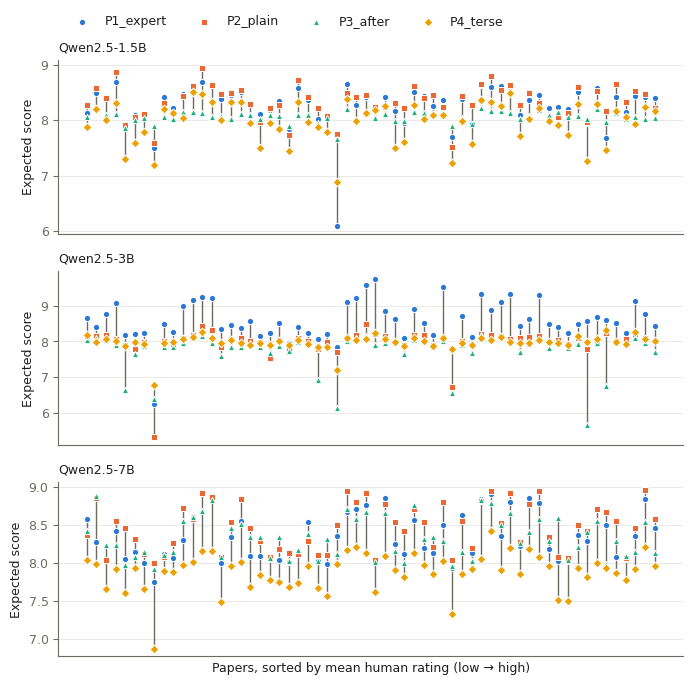

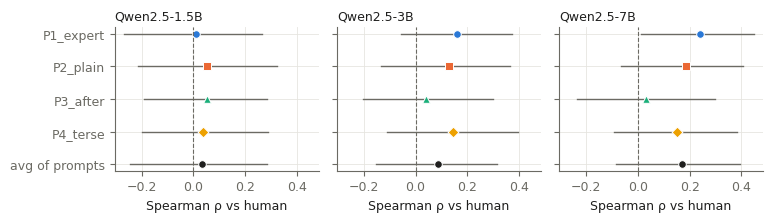

Done. Download data/ and results/ from the Output tab.


In [21]:
import matplotlib.pyplot as plt

COLORS = dict(zip(PROMPTS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))   # colorblind-validated categorical order
MARKERS = dict(zip(PROMPTS, ["o", "s", "^", "D"]))                           # shape = second encoding, never color alone
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e6e5e0"
plt.rcParams.update({"font.size": 9, "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})

def save(fig, name):
    fig.savefig(f"{OUT}/results/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT}/results/{name}.pdf", bbox_inches="tight")
    plt.show()

# Figure 1: each paper's expected score under the four prompts, papers sorted by mean human rating
fig, axes = plt.subplots(len(MODEL_IDS), 1, figsize=(7, 2.3 * len(MODEL_IDS)), squeeze=False)
for ax, model_id in zip(axes[:, 0], MODEL_IDS):
    wide = wide_scores(model_id)
    wide = wide.loc[meta.loc[wide.index].sort_values("human_mean").index]
    xs = np.arange(len(wide))
    ax.vlines(xs, wide.min(axis=1), wide.max(axis=1), color=MUTED, linewidth=1, zorder=1)
    for p in wide.columns:
        ax.scatter(xs, wide[p], s=20, marker=MARKERS[p], color=COLORS[p], edgecolor="white", linewidth=0.7,
                   label=p, zorder=2)
    ax.set_xticks([])
    ax.set_ylabel("Expected score")
    ax.set_title(short(model_id), loc="left", fontsize=9)
axes[-1, 0].set_xlabel("Papers, sorted by mean human rating (low → high)")
axes[0, 0].legend(ncol=4, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.12))
fig.tight_layout()
save(fig, "fig1_score_spread")

# Figure 2: agreement with human reviewers per prompt (Spearman ρ with 95% CI); 0 = no agreement
labels = list(PROMPTS) + ["avg of prompts"]
fig, axes = plt.subplots(1, len(MODEL_IDS), figsize=(2.6 * len(MODEL_IDS), 2.3), sharex=True, sharey=True, squeeze=False)
for ax, model_id in zip(axes[0], MODEL_IDS):
    m = metrics[model_id]
    for yv, p in enumerate(labels):
        v = m["prompt_averaged"] if p == "avg of prompts" else m["per_prompt"][p]
        lo, hi = v["spearman_ci"]
        ax.plot([lo, hi], [yv, yv], color=MUTED, linewidth=1, zorder=1)
        ax.scatter(v["spearman_vs_human"], yv, s=30, marker=MARKERS.get(p, "o"), color=COLORS.get(p, INK),
                   edgecolor="white", linewidth=0.7, zorder=2)
    ax.axvline(0, color=MUTED, linestyle="--", linewidth=0.8)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Spearman ρ vs human")
    ax.set_title(short(model_id), loc="left", fontsize=9)
axes[0, 0].invert_yaxis()
fig.tight_layout()
save(fig, "fig2_agreement")

print("Done. Download data/ and results/ from the Output tab.")